### Max energy transfer (elastic collision)

For a projectile of mass $m$ and speed $v$ scattering elastically from a target nucleus of mass $M$ initially at rest, the **maximum** energy transferred to the target (maximum recoil energy) is

$$
T_{\max} = \frac{4 m M}{(m+M)^2}\,K
$$

where the projectile kinetic energy is

$$
K = \tfrac12 m v^2.
$$

Equivalently, with reduced mass $\mu = \frac{mM}{m+M}$,

$$
T_{\max} = \frac{2\mu^2}{M} v^2.
$$

In [ ]:
import numpy as np
AMU_TO_KG  = 1.66053906660e-27  # kg/amu
EV_TO_J    = 1.60217663e-19     # J/eV
KEV_TO_J   = EV_TO_J * 1e3
GEV_TO_AMU = 1e9 / 931.494e6   # GeV/c² → amu

# DM projectile: 20 GeV/c² at 220 km/s
m_dm     = 20.0 * GEV_TO_AMU   # amu
v_dm     = 220e3                # m/s
K_dm_keV = 0.5 * m_dm * AMU_TO_KG * v_dm**2 / KEV_TO_J

# Max recoil energy for each target nucleus
# F, Ar, Xe: (name, Z, M_amu)
targets = [('F',  9,  18.998),
           ('Ar', 18, 39.948),
           ('Xe', 54, 131.293)]

K_recoil = {}
for name, Z, M in targets:
    Tmax = 4 * m_dm * M / (m_dm + M)**2 * K_dm_keV
    K_recoil[name] = Tmax
    print(f"{name:3s}  M = {M:7.3f} amu   K_max = {Tmax:.4f} keV")

K1_keV, K2_keV, K3_keV = K_recoil['F'], K_recoil['Ar'], K_recoil['Xe']

: 

### Stopping power via ZBL (Ziegler-Biersack-Littmark)

**Universal screening length**
$$a_U = \frac{0.8854\,a_0}{Z_1^{0.23}+Z_2^{0.23}}, \quad a_0 = 0.529\,\text{Å}$$

**Reduced energy**
$$\varepsilon = \frac{a_U \,M_2}{Z_1 Z_2\,e^2\,(M_1+M_2)}\,E, \quad e^2 = 14.4\,\text{eV Å}$$

**Reduced nuclear stopping** $s_n(\varepsilon)$
$$s_n = \begin{cases} \dfrac{\ln(1+1.1383\,\varepsilon)}{2\!\left(\varepsilon + 0.01321\,\varepsilon^{0.21226} + 0.19593\,\varepsilon^{0.5}\right)} & \varepsilon \le 30 \\[6pt] \dfrac{\ln\varepsilon}{2\varepsilon} & \varepsilon > 30 \end{cases}$$

**Nuclear stopping cross-section** (eV·Å²)
$$S_n(E) = \frac{4\pi\,a_U\,Z_1 Z_2\,e^2\,M_1}{M_1+M_2}\,s_n(\varepsilon)$$

**Electronic stopping** (Lindhard–Scharff, low energy)
$$S_e(E) = k_e\,\sqrt{E}, \quad k_e = 0.0793\,\frac{Z_1^{2/3}Z_2^{1/2}(M_1+M_2)^{3/2}}{(Z_1^{2/3}+Z_2^{2/3})^{3/4}\,M_1^{3/2}M_2^{1/2}}$$

Total stopping power: $dE/dx\,[\text{eV/Å}] = N\,(S_n + S_e)$ where $N$ is the target atomic density.

> **Reference:** J.F. Ziegler, M.D. Ziegler, J.P. Biersack, *SRIM – The stopping and range of ions in matter (2010)*, Nucl. Instrum. Methods Phys. Res. B **268**, 1818–1823 (2010). doi:[10.1016/j.nimb.2010.02.091](https://doi.org/10.1016/j.nimb.2010.02.091)

Ion  Medium         E            Sn/ρ            Se/ρ          Stot/ρ   [MeV·cm²/g]
──────────────────────────────────────────────────────────────────────────────
F    CF₄       K_max       1210.6418         32.0654       1242.7072
F    CF₄      10 keV       1166.4691         43.7771       1210.2462
Ar   Ar        K_max       1544.1775         15.2899       1559.4674
Ar   Ar       10 keV       1754.7475         21.8475       1776.5950
Xe   Xe        K_max       1080.5192          3.8906       1084.4098
Xe   Xe       10 keV       1933.9784          7.6272       1941.6056

Ion   ρ (g/cm³)         E    dEdx_n (keV/nm)    dEdx_e (keV/nm)   dEdx_tot (keV/nm)
──────────────────────────────────────────────────────────────────────────────────
F         1.700     K_max           0.205809           0.005451            0.211260
F         1.700    10 keV           0.198300           0.007442            0.205742
Ar        1.400     K_max           0.216185           0.002141            0.218325
Ar 

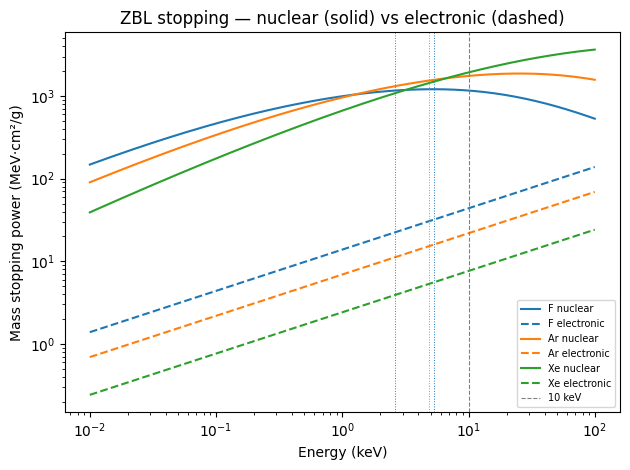

In [10]:
import matplotlib.pyplot as plt

A0_ANG = 0.52917721   # Bohr radius, Å
E2_EVA = 14.3996      # e²/(4πε₀), eV·Å
EV_A2_PER_AMU_TO_MEV_CM2_PER_G = 1e-22 / 1.66054e-24

def zbl_cross_section(Z1, M1, Z2, M2, E_eV):
    """ZBL stopping cross sections (eV·Å²/atom). Returns (Sn, Se)."""
    aU  = 0.8854 * A0_ANG / (Z1**0.23 + Z2**0.23)
    eps = aU * M2 / (Z1 * Z2 * E2_EVA * (M1 + M2)) * E_eV
    sn  = np.where(eps <= 30,
                   np.log(1 + 1.1383*eps) / (2*(eps + 0.01321*eps**0.21226 + 0.19593*eps**0.5)),
                   np.log(eps) / (2*eps))
    Sn = 4*np.pi * aU * Z1*Z2 * E2_EVA * M1/(M1+M2) * sn
    ke = (0.0793 * Z1**(2/3) * Z2**0.5 * (M1+M2)**1.5
          / ((Z1**(2/3) + Z2**(2/3))**0.75 * M1**1.5 * M2**0.5))
    Se = ke * np.sqrt(E_eV)
    return Sn, Se

ions = [('F',  9,  18.998),
        ('Ar', 18, 39.948),
        ('Xe', 54, 131.293)]

M_CF4 = 12.011 + 4*18.998
media = {
    'F':  [(6, 12.011, 12.011/M_CF4), (9, 18.998, 4*18.998/M_CF4)],
    'Ar': [(18, 39.948, 1.0)],
    'Xe': [(54, 131.293, 1.0)],
}
medium_label = {'F': 'CF₄', 'Ar': 'Ar', 'Xe': 'Xe'}
densities     = {'F': 1.7,   'Ar': 1.4,  'Xe': 3.0}

def stopping_at(name, Z1, M1, E_keV):
    """Returns (Sn_mass, Se_mass) in MeV·cm²/g at given energy in keV."""
    Sn_m = 0.0
    Se_m = 0.0
    for Z2, M2, w in media[name]:
        Sn, Se = zbl_cross_section(Z1, M1, Z2, M2, E_keV * 1e3)
        Sn_m += w * Sn / M2 * EV_A2_PER_AMU_TO_MEV_CM2_PER_G
        Se_m += w * Se / M2 * EV_A2_PER_AMU_TO_MEV_CM2_PER_G
    return Sn_m, Se_m

# --- Mass stopping power table ---
eval_energies = lambda name: [('K_max', K_recoil[name]), ('10 keV', 10.0)]

print(f"{'Ion':3s}  {'Medium':5s}  {'E':>8s}  {'Sn/ρ':>14s}  {'Se/ρ':>14s}  {'Stot/ρ':>14s}   [MeV·cm²/g]")
print("─" * 78)
mass_stop = {}
for name, Z1, M1 in ions:
    for label, E_keV in eval_energies(name):
        Sn_m, Se_m = stopping_at(name, Z1, M1, E_keV)
        mass_stop[(name, label)] = (Sn_m, Se_m)
        print(f"{name:3s}  {medium_label[name]:5s}  {label:>8s}  {Sn_m:>14.4f}  {Se_m:>14.4f}  {Sn_m+Se_m:>14.4f}")

# --- dE/dx in keV/nm ---
print(f"\n{'Ion':3s}  {'ρ (g/cm³)':>10s}  {'E':>8s}  {'dEdx_n (keV/nm)':>17s}  {'dEdx_e (keV/nm)':>17s}  {'dEdx_tot (keV/nm)':>18s}")
print("─" * 82)
for name, Z1, M1 in ions:
    rho = densities[name]
    for label, E_keV in eval_energies(name):
        Sn_m, Se_m = mass_stop[(name, label)]
        dEdx_n, dEdx_e = Sn_m * rho * 1e-4, Se_m * rho * 1e-4
        print(f"{name:3s}  {rho:>10.3f}  {label:>8s}  {dEdx_n:>17.6f}  {dEdx_e:>17.6f}  {dEdx_n+dEdx_e:>18.6f}")

# --- Nuclear vs electronic curves ---
E_eV = np.logspace(1, 5, 400)
colors = {'F': 'C0', 'Ar': 'C1', 'Xe': 'C2'}
fig, ax = plt.subplots()
for name, Z1, M1 in ions:
    Sn_m = np.zeros(len(E_eV))
    Se_m = np.zeros(len(E_eV))
    for Z2, M2, w in media[name]:
        Sn, Se = zbl_cross_section(Z1, M1, Z2, M2, E_eV)
        Sn_m += w * Sn / M2 * EV_A2_PER_AMU_TO_MEV_CM2_PER_G
        Se_m += w * Se / M2 * EV_A2_PER_AMU_TO_MEV_CM2_PER_G
    c = colors[name]
    ax.loglog(E_eV/1e3, Sn_m, ls='-',  color=c, label=f'{name} nuclear')
    ax.loglog(E_eV/1e3, Se_m, ls='--', color=c, label=f'{name} electronic')
    ax.axvline(K_recoil[name], color=c, lw=0.7, ls=':')
ax.axvline(10, color='gray', lw=0.8, ls='--', label='10 keV')
ax.set_xlabel('Energy (keV)')
ax.set_ylabel('Mass stopping power (MeV·cm²/g)')
ax.set_title('ZBL stopping — nuclear (solid) vs electronic (dashed)')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()